In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import datasets as load_datasets

#Loading data
datasets = load_datasets.load_dataset('lukebarousse/data_jobs')
df = datasets['train'].to_pandas()

#Data cleaning
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [23]:
df_US = df[df['job_country'] == 'United States']

In [24]:
df_US['job_posted_month'] = df_US['job_posted_date'].dt.strftime('%B')

In [25]:
df_Pivot = df_US.pivot_table(
    index='job_posted_month',
    columns='job_title_short',
    aggfunc='size'
)

In [26]:
df_Pivot.reset_index(inplace=True)

df_Pivot['month_no'] = pd.to_datetime(df_Pivot['job_posted_month'], format='%B').dt.month
df_Pivot.sort_values('month_no', inplace=True)
df_Pivot.set_index('job_posted_month', inplace=True)
df_Pivot.drop(columns='month_no', inplace=True)

In [27]:
df_Pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
January,527,36,8494,2655,6915,60,1544,773,1552,114
February,447,24,6124,3060,4956,56,1258,878,1127,90
March,438,19,6218,3183,4779,59,1114,829,1150,115
April,565,40,6049,2801,4867,51,1025,781,991,112
May,279,20,4993,2976,4377,49,839,746,914,90
June,446,32,5683,2893,4645,48,1009,812,1033,93
July,581,39,5201,2570,4876,65,883,747,1095,153
August,903,39,6634,3269,6318,68,1186,903,1515,194
September,897,50,4639,3224,4568,113,805,775,1014,228


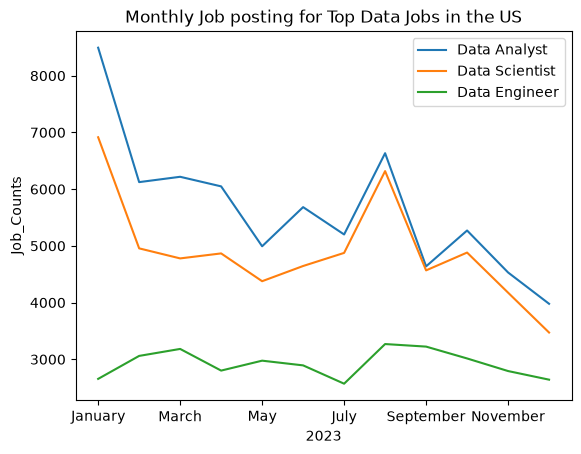

In [31]:
top_3 = df_US['job_title_short'].value_counts().head(3)
top_3 = top_3.index.tolist()
df_Pivot[top_3].plot(kind='line')
plt.title('Monthly Job posting for Top Data Jobs in the US')
plt.xlabel('2023')
plt.ylabel('Job_Counts')
plt.legend()
plt.show()